# Natural Cluster Grouping Loss Analysis

Analyze whether LLM performance varies across **naturally discovered clusters** (from Wikipedia embeddings)
rather than predefined cultural groups.

**Pipeline:**
1. Cluster entities per language using the same pipeline as notebook 03_01 (K-Means, Hierarchical, HDBSCAN)
2. Load LLM results from `llm_results.jsonl`
3. Merge: each LLM result gets the cluster from the embedding space of the same language
4. Compute grouping loss (accuracy variance / max-gap across clusters)
5. Compare against cultural-group baseline from notebook 05

In [52]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
import umap
import logging
from tqdm import tqdm

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(name)s - %(levelname)s - %(message)s")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use("default")
sns.set_palette("husl")

from src.embeddings import load_cached_embeddings
from src.clustering import (
    cluster_kmeans,
    cluster_hdbscan,
    cluster_hierarchical,
    find_optimal_k_kmeans,
)
from src.analysis import analyze_cluster_group_correlation

print("✓ Libraries imported")
print(f"✓ Random seed: {RANDOM_SEED}")

✓ Libraries imported
✓ Random seed: 42


## Section 1: Clustering per Language

Run the same pipeline as `03_01_clustering_analysis.ipynb` for **each of the 3 languages**.
This gives language-specific cluster assignments that reflect how entities are organized
in each language's semantic space.

In [53]:
CACHE_DIR = Path('../data/embeddings')
MODEL_NAME = "intfloat_multilingual-e5-large"
LANGUAGES = ['en', 'fr', 'ar']
N_PCA_COMPONENTS = 300
HDBSCAN_MIN_CLUSTER_SIZE = 115  # same as 03_01: ~0.5% of 23007


# Load entity metadata (index = entity id, 1-based)
entities_df = pd.read_csv('../data/experiment/selected_entities.csv')
print(f"✓ Loaded {len(entities_df)} entities")
print(f"  Cultures: {entities_df['culture'].value_counts().to_dict()}")

✓ Loaded 23007 entities
  Cultures: {'Western': 6010, 'Latin American': 5150, 'East Asian': 4096, 'Arabic': 3714, 'African': 2329, 'South Asian': 1247, 'Southeast Asian': 461}


In [54]:
entities_df

,id,wikidata_id,type,culture,country,created_at,label,labels,num_wikipedia_languages,birth_year,occupation_en,occupation_fr,occupation_ar,sex,occupation_group
0,1,Q10738,person,Western,United States,2025-12-17 00:26:11,Dwayne Johnson,"{'ar': 'دوين جونسون', 'en': 'Dwayne Johnson', ...",102,1972.0,Canadian football player,joueur de football canadien,لاعب كرة قدم كندية,male,Sports
1,2,Q10731,person,Western,United States,2025-12-17 00:26:19,Mick Foley,"{'ar': 'ميك فولي', 'en': 'Mick Foley', 'fr': '...",36,1965.0,writer,écrivain ou écrivaine,كاتب,male,Arts & Entertainment
2,3,Q1124,person,Western,United States,2025-12-17 00:26:23,Bill Clinton,"{'ar': 'بيل كلينتون', 'en': 'Bill Clinton', 'f...",174,1946.0,lawyer,avocat ou avocate,محام,male,Politics & Law
3,4,Q1744,person,Western,United States,2025-12-17 00:26:28,Madonna,"{'ar': 'مادونا', 'en': 'Madonna', 'fr': 'Madon...",154,1958.0,actor,acteur ou actrice,ممثل,female,Arts & Entertainment
4,5,Q4349,person,Western,United States,2025-12-17 00:26:33,Jimmy Bennett,"{'ar': 'جيمي بينيت', 'en': 'Jimmy Bennett', 'f...",30,1996.0,actor,acteur ou actrice,ممثل,male,Arts & Entertainment
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23002,37245,Q18127720,person,Latin American,Chile,2026-01-01 10:10:34,Rodrigo Salinas Muñoz,"{'ar': 'رودريجو ساليناس مونيوز', 'en': 'Rodrig...",11,1989.0,handball player,handballeur ou handballeuse,لاعب كرة يد,male,Sports
23003,37246,Q6524166,person,Latin American,Chile,2026-01-01 10:10:34,Leo Rey,"{'ar': 'ليو ري', 'en': 'Leo Rey', 'fr': 'Leo R...",6,1979.0,singer,chanteur ou chanteuse,مغني,male,Arts & Entertainment
23004,37247,Q6968078,person,Latin American,Chile,2026-01-01 10:10:34,Natalia Romero,"{'ar': 'ناتاليا روميرو', 'en': 'Natalia Romero...",12,1980.0,athletics competitor,athlète,منافس ألعاب قوى,female,Other
23005,37252,Q106904381,person,Latin American,Chile,2026-01-01 10:10:34,Elisa Loncon,"{'ar': 'إليسا لونكون', 'en': 'Elisa Loncon', '...",17,1963.0,politician,personnalité politique,سياسي,female,Politics & Law


In [55]:
def cluster_language(language, entities_df, cache_dir, model_name,
                     n_pca=300, random_seed=42, hdbscan_min_size=115):
    """
    Run the full clustering pipeline for one language.
    Replicates 03_01_clustering_analysis.ipynb exactly.

    Returns dict with:
      - labels_kmeans, labels_hierarchical, labels_hdbscan (np arrays, len=n_entities)
      - optimal_k
      - embeddings_umap (2D, for visualization)
      - pca_embeddings (for later use)
    """
    print(f"\n{'='*70}")
    print(f"CLUSTERING: {language.upper()}")
    print(f"{'='*70}")

    # 1. Load embeddings
    emb_data = load_cached_embeddings(language=language, model_name=model_name, save_dir=cache_dir, text_type='content')
    embeddings = emb_data['embeddings']
    print(f"✓ Embeddings: {embeddings.shape}")

    # 2. L2 normalize
    embeddings_norm = normalize(embeddings, norm='l2', axis=1)

    # 3. PCA
    pca = PCA(n_components=min(n_pca, embeddings_norm.shape[1]), random_state=random_seed)
    embeddings_pca = pca.fit_transform(embeddings_norm)
    embeddings_pca = normalize(embeddings_pca, norm='l2', axis=1)
    print(f"✓ PCA: {embeddings_pca.shape}, variance explained: {pca.explained_variance_ratio_.sum():.2%}")

    # 4. Find optimal k for K-Means (small range for speed — 03_01 found k=2 for EN & AR)
    k_range = range(2, 21)
    k_results = find_optimal_k_kmeans(embeddings_pca, k_range=k_range, random_state=random_seed)
    optimal_k = k_results['optimal_k']['silhouette']
    print(f"✓ Optimal k (silhouette): {optimal_k}")

    # 5. K-Means
    labels_kmeans = cluster_kmeans(embeddings_pca, n_clusters=optimal_k, random_state=random_seed)
    cluster_counts = {c: int((labels_kmeans == c).sum()) for c in sorted(set(labels_kmeans))}
    print(f"✓ K-Means clusters: {cluster_counts}")

    # 6. Hierarchical (ward linkage)
    labels_hierarchical = cluster_hierarchical(
        embeddings_pca, n_clusters=optimal_k, linkage='ward', metric='euclidean'
    )
    print(f"✓ Hierarchical (ward) clusters: {len(set(labels_hierarchical))}")

    # 7. HDBSCAN
    labels_hdbscan = cluster_hdbscan(
        embeddings_pca, min_cluster_size=hdbscan_min_size, min_samples=1
    )
    n_hdb = len(set(labels_hdbscan)) - (1 if -1 in labels_hdbscan else 0)
    n_noise = (labels_hdbscan == -1).sum()
    print(f"✓ HDBSCAN: {n_hdb} clusters, {n_noise} noise ({100*n_noise/len(labels_hdbscan):.1f}%)")

    # 8. UMAP 2D for visualization
    print("Computing UMAP (2D)...")
    umap_model = umap.UMAP(n_components=2, random_state=random_seed, n_neighbors=15, min_dist=0.1)
    embeddings_umap = umap_model.fit_transform(embeddings_pca)
    print(f"✓ UMAP: {embeddings_umap.shape}")

    return {
        'labels_kmeans': labels_kmeans,
        'labels_hierarchical': labels_hierarchical,
        'labels_hdbscan': labels_hdbscan,
        'optimal_k': optimal_k,
        'embeddings_umap': embeddings_umap,
        'embeddings_pca': embeddings_pca,
    }

print("✓ Clustering function defined")

✓ Clustering function defined


In [56]:
# Run clustering for all 3 languages
# This takes several minutes per language (PCA + clustering + UMAP)
clusters_per_language = {}

for lang in LANGUAGES:
    clusters_per_language[lang] = cluster_language(
        language=lang,
        entities_df=entities_df,
        cache_dir=CACHE_DIR,
        model_name=MODEL_NAME,
        n_pca=N_PCA_COMPONENTS,
        random_seed=RANDOM_SEED,
        hdbscan_min_size=HDBSCAN_MIN_CLUSTER_SIZE,
    )

print("\n✓ Clustering complete for all languages")
for lang in LANGUAGES:
    c = clusters_per_language[lang]
    print(f"  {lang}: k={c['optimal_k']}, "
          f"kmeans clusters={len(set(c['labels_kmeans']))}, "
          f"hdbscan clusters={len(set(c['labels_hdbscan'])) - (1 if -1 in c['labels_hdbscan'] else 0)}")

2026-03-13 16:42:14,623 - src.embeddings.text_embedder - INFO - Loading cached embeddings from ../data/embeddings/embeddings_en_content_intfloat_multilingual-e5-large.pkl



CLUSTERING: EN


2026-03-13 16:42:14,759 - src.embeddings.text_embedder - INFO - Loaded embeddings shape: (23007, 1024)
2026-03-13 16:42:14,759 - src.embeddings.text_embedder - INFO - Number of entities: 23007


✓ Embeddings: (23007, 1024)


2026-03-13 16:42:18,669 - src.clustering.cluster_methods - INFO - Finding optimal k in range range(2, 21)


...

✓ K-Means clusters: {np.int32(0): 13585, np.int32(1): 9422}


2026-03-13 16:55:59,071 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters
2026-03-13 16:55:59,084 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=115, min_samples=1


✓ Hierarchical (ward) clusters: 2


2026-03-13 16:56:56,506 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 15 clusters, 15651 noise points
/home/khaledbouabdallah/repos/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


✓ HDBSCAN: 15 clusters, 15651 noise (68.0%)
Computing UMAP (2D)...
✓ UMAP: (23007, 2)

✓ Clustering complete for all languages
  en: k=2, kmeans clusters=2, hdbscan clusters=14
  fr: k=2, kmeans clusters=2, hdbscan clusters=7
  ar: k=2, kmeans clusters=2, hdbscan clusters=15


## Section 2: Load LLM Results and Merge with Clusters

In [95]:
RESULTS_PATH = Path('../data/experiment/llm_results.jsonl')

results = []
with open(RESULTS_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            results.append(json.loads(line))

results_df = pd.DataFrame(results)

print(f"✓ Loaded {len(results_df):,} LLM results")
print(f"  Columns: {results_df.columns.tolist()}")
print(f"  Languages: {results_df['language'].value_counts().to_dict()}")
print(f"  Question types: {results_df['question_type'].value_counts().to_dict()}")
print(f"  Overall accuracy: {results_df['is_correct'].mean():.2%}")

✓ Loaded 205,098 LLM results
  Columns: ['question_id', 'entity_id', 'question_type', 'language', 'correct_answer', 'predicted_answer', 'is_correct', 'probabilities', 'confidence', 'correct_prob', 'timestamp']
  Languages: {'en': 68366, 'fr': 68366, 'ar': 68366}
  Question types: {'birth_place': 69021, 'birth_date': 69021, 'nationality': 67056}
  Overall accuracy: 48.11%


In [96]:
# Merge LLM results with entity metadata
results_with_meta = results_df.merge(
    entities_df[['id', 'culture', 'country', 'wikidata_id']],
    left_on='entity_id',
    right_on='id',
    how='left',
    suffixes=('', '_entity')
)

print(f"✓ Merged with entity metadata: {len(results_with_meta):,} rows")
print(f"  NaN cultures: {results_with_meta['culture'].isna().sum()}")

# Build per-language cluster DataFrames (entity_id → cluster labels)
# entities_df rows correspond 1:1 with embedding rows (same order, id is row position + 1)
combined_parts = []

for lang in LANGUAGES:
    c = clusters_per_language[lang]

    lang_clusters = entities_df[['id']].copy()
    lang_clusters['cluster_kmeans'] = c['labels_kmeans']
    lang_clusters['cluster_hierarchical'] = c['labels_hierarchical']
    lang_clusters['cluster_hdbscan'] = c['labels_hdbscan']

    lang_results = results_with_meta[results_with_meta['language'] == lang].copy()
    lang_results = lang_results.merge(
        lang_clusters.rename(columns={'id': 'entity_id'}),
        on='entity_id',
        how='left'
    )
    combined_parts.append(lang_results)

merged_df = pd.concat(combined_parts, ignore_index=True)

print(f"\n✓ Final merged DataFrame: {len(merged_df):,} rows")
print(f"  NaN cluster_kmeans: {merged_df['cluster_kmeans'].isna().sum()}")
print(f"  Languages: {merged_df['language'].value_counts().to_dict()}")

✓ Merged with entity metadata: 205,098 rows
  NaN cultures: 0

✓ Final merged DataFrame: 205,098 rows
  NaN cluster_kmeans: 0
  Languages: {'en': 68366, 'fr': 68366, 'ar': 68366}


## Section 3: Grouping Loss Calculations

In [97]:

# =============================================================================
# Grouping Loss via ECE decomposition (Chen et al., EMNLP 2024)
#
# Per-question calibration error = |confidence - is_correct|
# Per-group ECE = mean(|confidence - is_correct|) across all questions in group
# Grouping Loss (variance) = variance of per-group ECEs
# Grouping Loss (max-gap)  = max ECE - min ECE across groups
#
# Intuition: even if overall ECE is low, some groups may be heavily
# overconfident → high variance of group ECEs = bias.
#
# confidence = probability the model assigned to its chosen answer (not
# the probability of the correct answer — that is correct_prob).
# =============================================================================


def group_ece(df, cluster_col, exclude_noise=True):
    """
    Compute ECE per group and derive grouping loss metrics.

    Returns dict:
      group_eces    : {group_id: ECE}      # per-group calibration error
      variance      : variance of group ECEs  (main grouping loss)
      max_gap       : max - min group ECE     (alternative metric)
      overall_ece   : ECE over whole df       (ignoring groups)
      overall_acc   : accuracy over whole df
      n_groups      : number of groups
    """
    sub = df.copy()
    if exclude_noise:
        sub = sub[sub[cluster_col] != -1]

    per_q_error = (sub['confidence'] - sub['is_correct'].astype(float)).abs()

    ece_per_group = {}
    acc_per_group = {}
    for gid, grp in sub.groupby(cluster_col):
        errors = (grp['confidence'] - grp['is_correct'].astype(float)).abs()
        ece_per_group[gid] = float(errors.mean())
        acc_per_group[gid] = float(grp['is_correct'].mean())

    vals = list(ece_per_group.values())
    return {
        'group_eces':   ece_per_group,
        'group_accs':   acc_per_group,
        'variance':     float(np.var(vals))             if len(vals) > 1 else 0.0,
        'max_gap':      float(max(vals) - min(vals))    if len(vals) > 1 else 0.0,
        'overall_ece':  float(per_q_error.mean()),
        'overall_acc':  float(sub['is_correct'].mean()),
        'n_groups':     len(vals),
    }


# alias used in rest of notebook
grouping_loss = group_ece


# --- compute for all (algorithm × language × question_type) ---
algorithms = {
    'kmeans':       'cluster_kmeans',
    'hierarchical': 'cluster_hierarchical',
    'hdbscan':      'cluster_hdbscan',
}

records = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang]
    for algo_name, col in algorithms.items():
        for qtype_filter, qtype_label in [
                (None, 'all'), ('birth_place', 'birth_place'),
                ('nationality', 'nationality'), ('birth_date', 'birth_date')]:
            sub = lang_df if qtype_filter is None else lang_df[lang_df['question_type'] == qtype_filter]
            gl = group_ece(sub, col)
            records.append({
                'language': lang, 'algorithm': algo_name, 'question_type': qtype_label,
                'n_groups': gl['n_groups'],
                'grouping_loss_variance': gl['variance'],
                'grouping_loss_gap':      gl['max_gap'],
                'overall_ece':            gl['overall_ece'],
                'overall_accuracy':       gl['overall_acc'],
                'group_eces':             gl['group_eces'],
                'group_accs':             gl['group_accs'],
            })

gl_df = pd.DataFrame(records)

display_cols = ['language', 'algorithm', 'question_type', 'n_groups',
                'grouping_loss_variance', 'grouping_loss_gap', 'overall_ece', 'overall_accuracy']

print("✓ Grouping loss computed via ECE decomposition")
print("  metric: variance / max-gap of per-group |confidence - is_correct|")
print(f"  {len(gl_df)} rows (lang × algo × question_type)\n")
print(gl_df[gl_df['question_type'] == 'all'][display_cols].to_string(index=False))


✓ Grouping loss computed via ECE decomposition
  metric: variance / max-gap of per-group |confidence - is_correct|
  36 rows (lang × algo × question_type)

language    algorithm question_type  n_groups  grouping_loss_variance  grouping_loss_gap  overall_ece  overall_accuracy
      en       kmeans           all         2                0.000644           0.050737     0.387854          0.588275
      en hierarchical           all         2                0.000538           0.046378     0.387854          0.588275
      en      hdbscan           all        14                0.003585           0.201126     0.364326          0.613059
      fr       kmeans           all         2                0.000170           0.026060     0.386739          0.584106
      fr hierarchical           all         2                0.000149           0.024397     0.386739          0.584106
      fr      hdbscan           all         7                0.002168           0.150235     0.377491          0.593841
    

In [98]:

# Grouping loss baseline: cultural labels (same methodology)
culture_records = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang].copy()
    lang_df['culture_int'] = lang_df['culture'].astype('category').cat.codes
    for qtype_filter, qtype_label in [
            (None, 'all'), ('birth_place', 'birth_place'),
            ('nationality', 'nationality'), ('birth_date', 'birth_date')]:
        sub = lang_df if qtype_filter is None else lang_df[lang_df['question_type'] == qtype_filter]
        gl = group_ece(sub, 'culture_int', exclude_noise=False)
        culture_records.append({
            'language': lang, 'algorithm': 'culture_baseline', 'question_type': qtype_label,
            'n_groups': gl['n_groups'],
            'grouping_loss_variance': gl['variance'],
            'grouping_loss_gap':      gl['max_gap'],
            'overall_ece':            gl['overall_ece'],
            'overall_accuracy':       gl['overall_acc'],
            'group_eces':             gl['group_eces'],
            'group_accs':             gl['group_accs'],
        })

culture_gl_df = pd.DataFrame(culture_records)
print("✓ Culture baseline grouping loss computed (ECE-based)")
print(culture_gl_df[culture_gl_df['question_type'] == 'all'][display_cols].to_string(index=False))


✓ Culture baseline grouping loss computed (ECE-based)
language        algorithm question_type  n_groups  grouping_loss_variance  grouping_loss_gap  overall_ece  overall_accuracy
      en culture_baseline           all         7                0.003124           0.181595     0.387854          0.588275
      fr culture_baseline           all         7                0.003105           0.171601     0.386739          0.584106
      ar culture_baseline           all         7                0.000237           0.042817     0.677306          0.270997


## Section 4: Visualizations

### 4.1 UMAP — Cluster Structure per Language

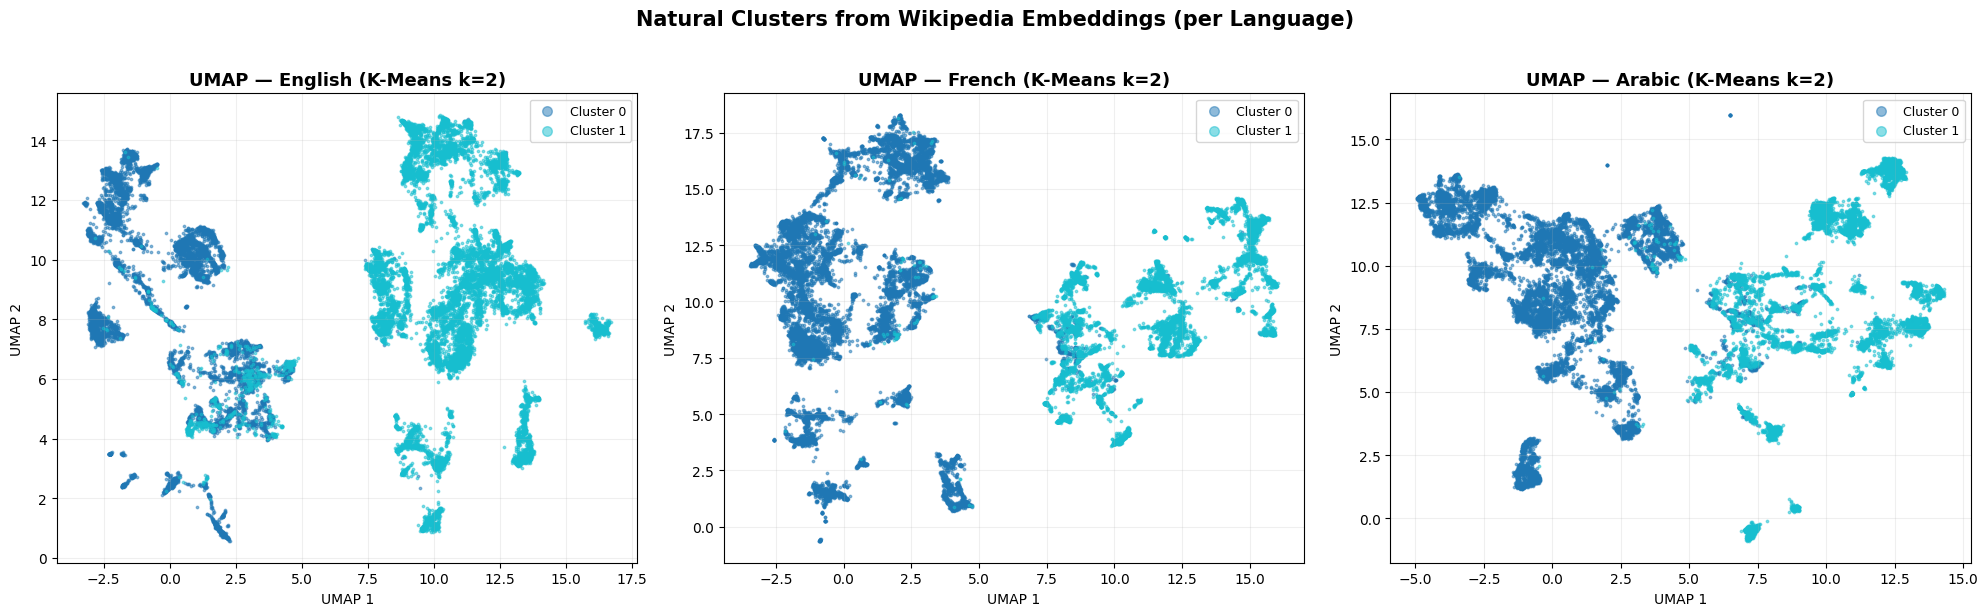

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
lang_labels_map = {'en': 'English', 'fr': 'French', 'ar': 'Arabic'}
cmap = plt.cm.tab10

for ax, lang in zip(axes, LANGUAGES):
    c = clusters_per_language[lang]
    umap_2d = c['embeddings_umap']
    labels = c['labels_kmeans']
    unique = sorted(set(labels))
    colors = cmap(np.linspace(0, 0.9, len(unique)))

    for cluster_id, color in zip(unique, colors):
        mask = labels == cluster_id
        ax.scatter(umap_2d[mask, 0], umap_2d[mask, 1],
                   c=[color], s=3, alpha=0.5, label=f'Cluster {cluster_id}')

    ax.set_title(f'UMAP — {lang_labels_map[lang]} (K-Means k={c["optimal_k"]})',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.legend(markerscale=4, fontsize=9)
    ax.grid(True, alpha=0.2)

plt.suptitle('Natural Clusters from Wikipedia Embeddings (per Language)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

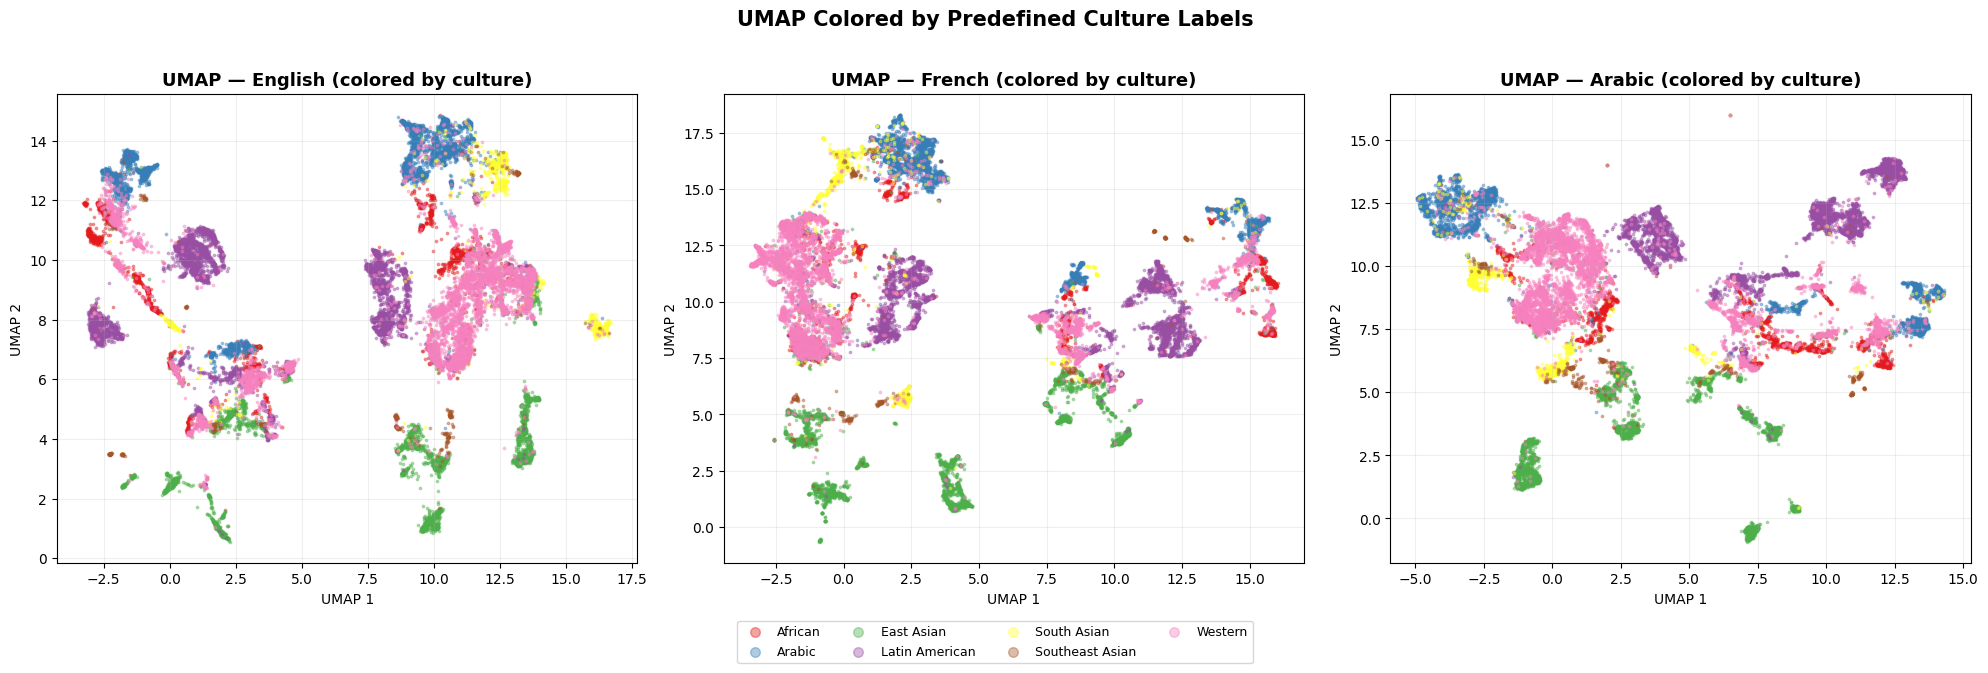

In [100]:
# UMAP colored by culture (to verify cluster ↔ culture relationship)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
cultures = sorted(entities_df['culture'].dropna().unique())
culture_palette = {c: plt.cm.Set1(i / len(cultures)) for i, c in enumerate(cultures)}

for ax, lang in zip(axes, LANGUAGES):
    c = clusters_per_language[lang]
    umap_2d = c['embeddings_umap']
    culture_labels = entities_df['culture'].values

    for cult in cultures:
        mask = culture_labels == cult
        ax.scatter(umap_2d[mask, 0], umap_2d[mask, 1],
                   c=[culture_palette[cult]], s=3, alpha=0.4, label=cult)

    ax.set_title(f'UMAP — {lang_labels_map[lang]} (colored by culture)',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.grid(True, alpha=0.2)

# Single legend outside
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.08), fontsize=9, markerscale=4)
plt.suptitle('UMAP Colored by Predefined Culture Labels', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.2 Accuracy Heatmap — Cluster × Language (K-Means)

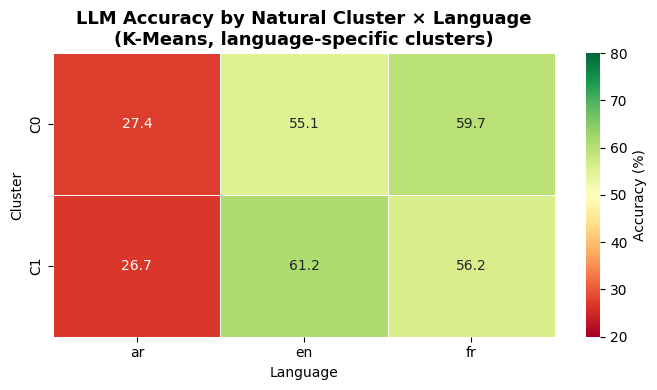


Accuracy table:
language    ar    en    fr
cluster                   
C0        27.4  55.1  59.7
C1        26.7  61.2  56.2


In [101]:
# Build cluster × language accuracy table for K-Means
rows = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang]
    for cluster_id, grp in lang_df.groupby('cluster_kmeans'):
        rows.append({'language': lang, 'cluster': f'C{cluster_id}', 'accuracy': grp['is_correct'].mean()})

heatmap_df = pd.DataFrame(rows).pivot(index='cluster', columns='language', values='accuracy') * 100

fig, ax = plt.subplots(figsize=(7, max(4, len(heatmap_df) * 0.7)))
sns.heatmap(heatmap_df, annot=True, fmt='.1f', cmap='RdYlGn', vmin=20, vmax=80,
            ax=ax, cbar_kws={'label': 'Accuracy (%)'}, linewidths=0.5)
ax.set_title('LLM Accuracy by Natural Cluster × Language\n(K-Means, language-specific clusters)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Language')
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.show()

print("\nAccuracy table:")
print(heatmap_df.round(1).to_string())

### 4.3 Grouping Loss Bar Chart — Natural Clusters vs Culture Baseline

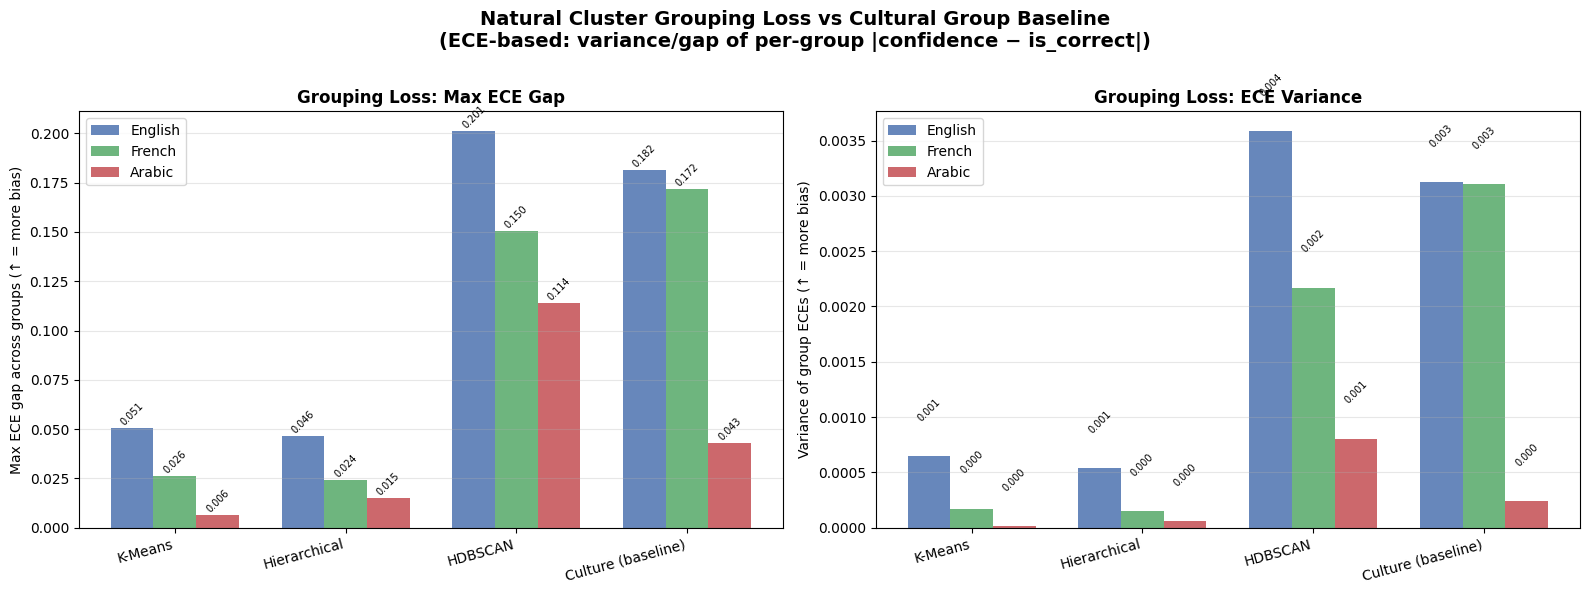


=== Culture baseline: per-group ECE ===

English  (overall ECE=0.388)
  African               ECE=0.398  acc=0.564
  Arabic                ECE=0.419  acc=0.550
  East Asian            ECE=0.307  acc=0.678
  Latin American        ECE=0.489  acc=0.477
  South Asian           ECE=0.405  acc=0.573
  Southeast Asian       ECE=0.364  acc=0.602
  Western               ECE=0.331  acc=0.658

French  (overall ECE=0.387)
  African               ECE=0.398  acc=0.559
  Arabic                ECE=0.435  acc=0.529
  East Asian            ECE=0.306  acc=0.674
  Latin American        ECE=0.478  acc=0.479
  South Asian           ECE=0.415  acc=0.559
  Southeast Asian       ECE=0.379  acc=0.580
  Western               ECE=0.325  acc=0.661

Arabic  (overall ECE=0.677)
  African               ECE=0.694  acc=0.247
  Arabic                ECE=0.667  acc=0.272
  East Asian            ECE=0.655  acc=0.303
  Latin American        ECE=0.698  acc=0.251
  South Asian           ECE=0.669  acc=0.264
  Southeast Asia

In [102]:

all_gl = pd.concat([gl_df, culture_gl_df], ignore_index=True)
plot_data = all_gl[all_gl['question_type'] == 'all'].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
algo_order = ['kmeans', 'hierarchical', 'hdbscan', 'culture_baseline']
algo_labels = {'kmeans': 'K-Means', 'hierarchical': 'Hierarchical',
               'hdbscan': 'HDBSCAN', 'culture_baseline': 'Culture (baseline)'}
colors = {'en': '#4C72B0', 'fr': '#55A868', 'ar': '#C44E52'}

for ax, metric, ylabel, title in [
    (axes[0], 'grouping_loss_gap',
     'Max ECE gap across groups (↑ = more bias)', 'Grouping Loss: Max ECE Gap'),
    (axes[1], 'grouping_loss_variance',
     'Variance of group ECEs (↑ = more bias)', 'Grouping Loss: ECE Variance'),
]:
    x = np.arange(len(algo_order))
    width = 0.25
    for i, lang in enumerate(LANGUAGES):
        vals = [plot_data[(plot_data['language'] == lang) & (plot_data['algorithm'] == algo)][metric].values[0]
                if len(plot_data[(plot_data['language'] == lang) & (plot_data['algorithm'] == algo)]) > 0
                else 0
                for algo in algo_order]
        bars = ax.bar(x + i * width, vals, width, label=lang_labels_map[lang],
                      color=colors[lang], alpha=0.85)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.0003,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=7, rotation=45)

    ax.set_xticks(x + width)
    ax.set_xticklabels([algo_labels[a] for a in algo_order], rotation=15, ha='right')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Natural Cluster Grouping Loss vs Cultural Group Baseline\n'
             '(ECE-based: variance/gap of per-group |confidence − is_correct|)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- reference table: group ECEs for culture baseline ---
print("\n=== Culture baseline: per-group ECE ===")
for lang in LANGUAGES:
    row = culture_gl_df[(culture_gl_df['language'] == lang) &
                        (culture_gl_df['question_type'] == 'all')].iloc[0]
    print(f"\n{lang_labels_map[lang]}  (overall ECE={row['overall_ece']:.3f})")
    cat_map = merged_df[merged_df['language'] == lang][['culture']].drop_duplicates()
    cat_map['code'] = cat_map['culture'].astype('category').cat.codes
    for _, r in cat_map.sort_values('code').iterrows():
        ece = row['group_eces'].get(r['code'], float('nan'))
        acc = row['group_accs'].get(r['code'], float('nan'))
        print(f"  {r['culture']:20s}  ECE={ece:.3f}  acc={acc:.3f}")


### 4.4 Calibration per Cluster (K-Means)

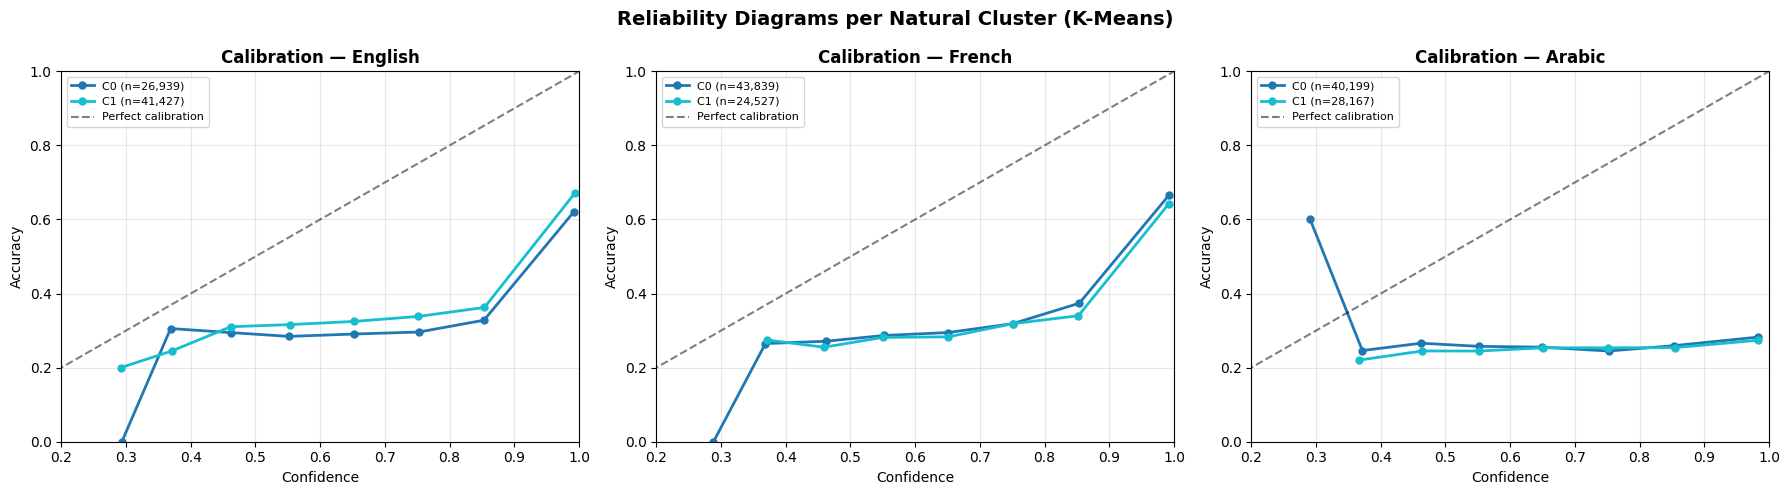

In [103]:
def reliability_diagram(ax, df, cluster_col, title, n_bins=10):
    """Plot reliability diagram (calibration curve) per cluster."""
    bins = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2

    clusters = sorted(df[cluster_col].unique())
    # Skip noise
    clusters = [c for c in clusters if c != -1]
    colors = plt.cm.tab10(np.linspace(0, 0.9, len(clusters)))

    for cluster_id, color in zip(clusters, colors):
        sub = df[df[cluster_col] == cluster_id].copy()
        # Bin by confidence
        sub['conf_bin'] = pd.cut(sub['confidence'], bins=bins, labels=bin_centers, include_lowest=True)
        calib = sub.groupby('conf_bin', observed=True).agg(
            accuracy=('is_correct', 'mean'),
            count=('is_correct', 'count'),
            mean_conf=('confidence', 'mean')
        ).dropna()

        ax.plot(calib['mean_conf'], calib['accuracy'], 'o-',
                label=f'C{cluster_id} (n={len(sub):,})', color=color, linewidth=2, markersize=5)

    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect calibration')
    ax.set_xlabel('Confidence')
    ax.set_ylabel('Accuracy')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.2, 1.0)
    ax.set_ylim(0, 1)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lang in zip(axes, LANGUAGES):
    lang_df = merged_df[merged_df['language'] == lang]
    reliability_diagram(ax, lang_df, 'cluster_kmeans',
                        f'Calibration — {lang_labels_map[lang]}')

plt.suptitle('Reliability Diagrams per Natural Cluster (K-Means)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.5 Accuracy by Cluster × Question Type

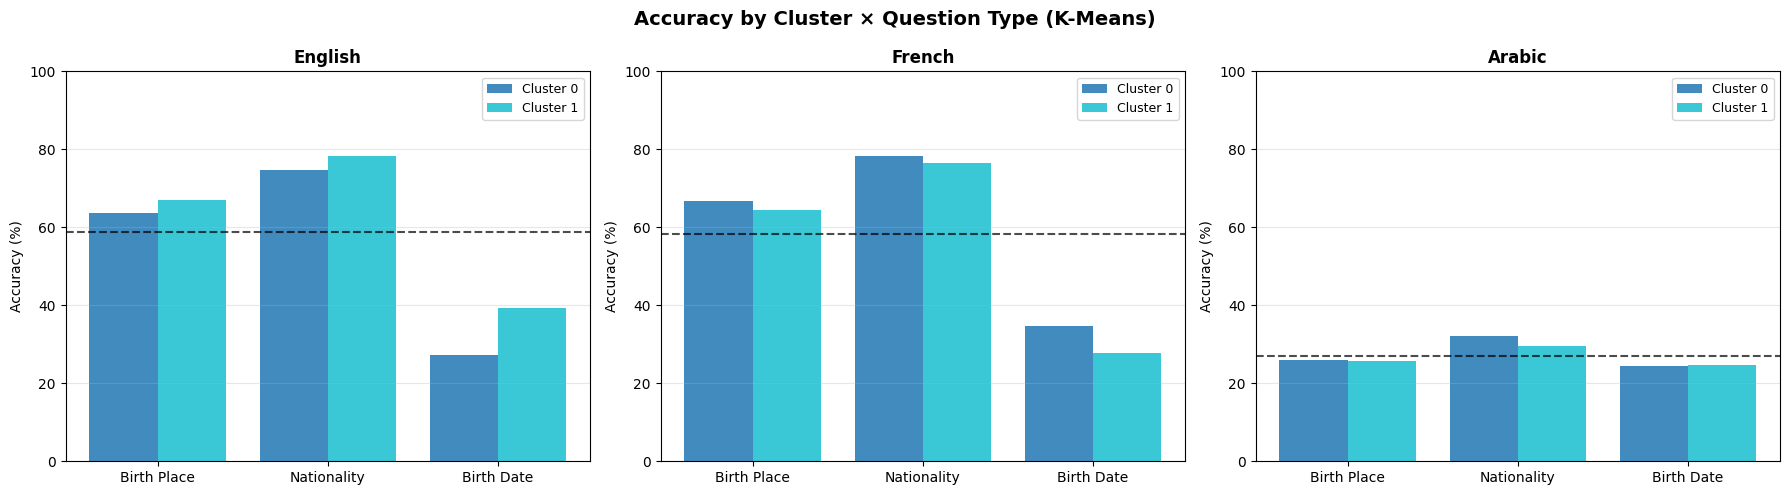

In [104]:
qtypes = ['birth_place', 'nationality', 'birth_date']
qtype_labels = {'birth_place': 'Birth Place', 'nationality': 'Nationality', 'birth_date': 'Birth Date'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, lang in zip(axes, LANGUAGES):
    lang_df = merged_df[merged_df['language'] == lang]
    clusters = sorted([c for c in lang_df['cluster_kmeans'].unique() if c != -1])

    x = np.arange(len(qtypes))
    width = 0.8 / len(clusters)
    colors = plt.cm.tab10(np.linspace(0, 0.9, len(clusters)))

    for i, (cluster_id, color) in enumerate(zip(clusters, colors)):
        sub = lang_df[lang_df['cluster_kmeans'] == cluster_id]
        accs = [sub[sub['question_type'] == qt]['is_correct'].mean() * 100 for qt in qtypes]
        bars = ax.bar(x + i * width - (len(clusters)-1)*width/2, accs, width,
                      label=f'Cluster {cluster_id}', color=color, alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels([qtype_labels[q] for q in qtypes])
    ax.set_ylim(0, 100)
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'{lang_labels_map[lang]}', fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')
    # Add overall line
    overall = lang_df['is_correct'].mean() * 100
    ax.axhline(overall, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label=f'Overall {overall:.1f}%')

plt.suptitle('Accuracy by Cluster × Question Type (K-Means)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [105]:
colors

array([[0.12156863, 0.46666667, 0.70588235, 1.        ],
       [0.09019608, 0.74509804, 0.81176471, 1.        ]])

### 4.6 Grouping Loss per Question Type (K-Means)

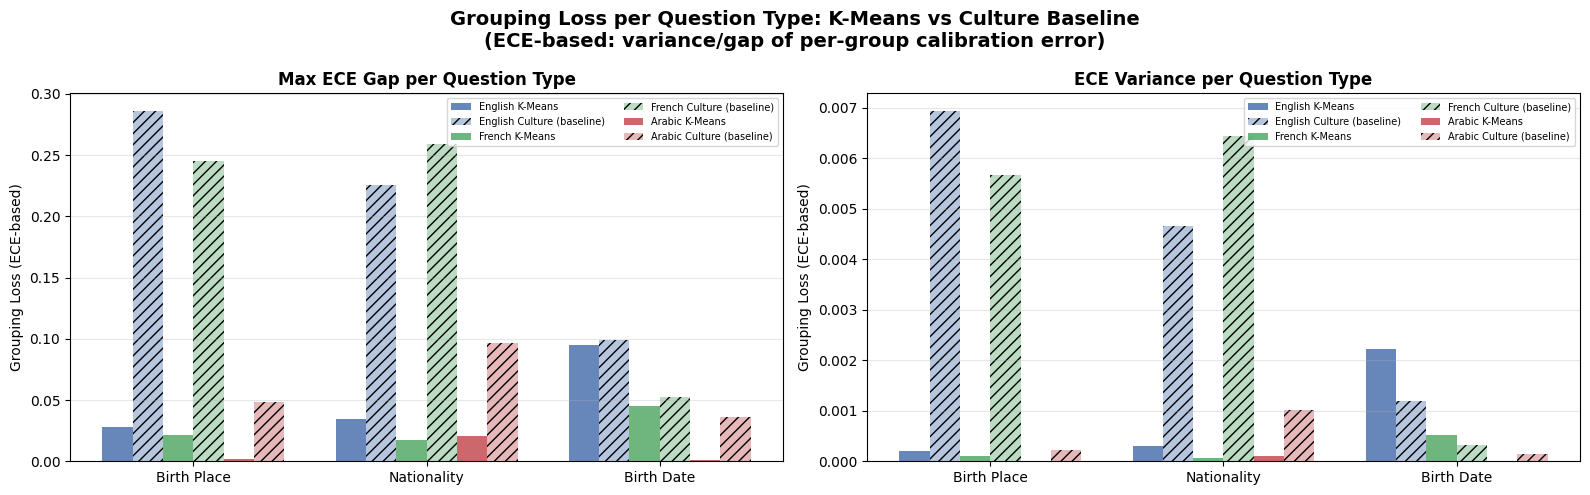

In [106]:

qtype_gl = all_gl[all_gl['algorithm'].isin(['kmeans', 'culture_baseline'])].copy()
qtype_gl = qtype_gl[qtype_gl['question_type'] != 'all']
colors = {'en': '#4C72B0', 'fr': '#55A868', 'ar': '#C44E52'}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, metric, title in [
    (axes[0], 'grouping_loss_gap',      'Max ECE Gap per Question Type'),
    (axes[1], 'grouping_loss_variance', 'ECE Variance per Question Type'),
]:
    x = np.arange(len(qtypes))
    width = 0.13
    slot = 0
    for lang in LANGUAGES:
        for algo, hatch in [('kmeans', ''), ('culture_baseline', '///')]:
            vals = [qtype_gl[(qtype_gl['language'] == lang) &
                             (qtype_gl['algorithm'] == algo) &
                             (qtype_gl['question_type'] == qt)][metric].values[0]
                    if len(qtype_gl[(qtype_gl['language'] == lang) &
                                    (qtype_gl['algorithm'] == algo) &
                                    (qtype_gl['question_type'] == qt)]) > 0 else 0
                    for qt in qtypes]
            offset = (slot - 2.5) * width
            label = f'{lang_labels_map[lang]} {algo_labels.get(algo, algo)}'
            ax.bar(x + offset, vals, width, label=label,
                   color=colors[lang], alpha=0.85 if algo == 'kmeans' else 0.4,
                   hatch=hatch)
            slot += 1

    ax.set_xticks(x)
    ax.set_xticklabels([qtype_labels[q] for q in qtypes])
    ax.set_ylabel('Grouping Loss (ECE-based)')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Grouping Loss per Question Type: K-Means vs Culture Baseline\n'
             '(ECE-based: variance/gap of per-group calibration error)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Section 4.7 — HDBSCAN Analysis: Noise as a Class

HDBSCAN found 7–15 clusters per language but labels 68% of entities as **noise** (label -1).
Rather than discarding these, we treat noise as an additional class.

Two changes to `merged_df`:
1. Add `occupation_group` (not included in the original merge)
2. Add `cluster_hdbscan_labeled`: noise → `"noise"`, clusters → `"C0"`, `"C1"`, …

In [107]:

# Add occupation_group to merged_df (not included in the original merge)
merged_df = merged_df.merge(
    entities_df[['id', 'occupation_group']],
    left_on='entity_id',
    right_on='id',
    how='left',
    suffixes=('', '_occ')
).drop(columns=['id_occ'], errors='ignore')

print(f"✓ occupation_group added")
print(f"  Distribution: {merged_df['occupation_group'].value_counts().to_dict()}")
print(f"  NaN: {merged_df['occupation_group'].isna().sum()}")

# Remap HDBSCAN noise (-1) → 'noise' label for visualization and heatmaps
merged_df['cluster_hdbscan_labeled'] = merged_df['cluster_hdbscan'].apply(
    lambda x: 'noise' if x == -1 else f'C{int(x)}'
)

n_noise = (merged_df['cluster_hdbscan'] == -1).sum()
n_total = len(merged_df)
print(f"\n✓ HDBSCAN noise remapped: {n_noise:,} noise rows ({100*n_noise/n_total:.1f}% of {n_total:,})")
print(f"  Sample (English): {merged_df[merged_df['language']=='en']['cluster_hdbscan_labeled'].value_counts().head(8).to_dict()}")


✓ occupation_group added
  Distribution: {'Sports': 81846, 'Arts & Entertainment': 55191, 'Politics & Law': 21885, 'Other': 20451, 'Science & Academia': 14571, 'Media & Journalism': 4284, 'Business & Finance': 2946, 'Military': 2571, 'Religious': 1353}
  NaN: 0

✓ HDBSCAN noise remapped: 131,917 noise rows (64.3% of 205,098)
  Sample (English): {'noise': 47660, 'C12': 11205, 'C8': 1314, 'C2': 1277, 'C9': 1210, 'C6': 1086, 'C10': 624, 'C3': 619}


### 4.8 UMAP — HDBSCAN Cluster Structure

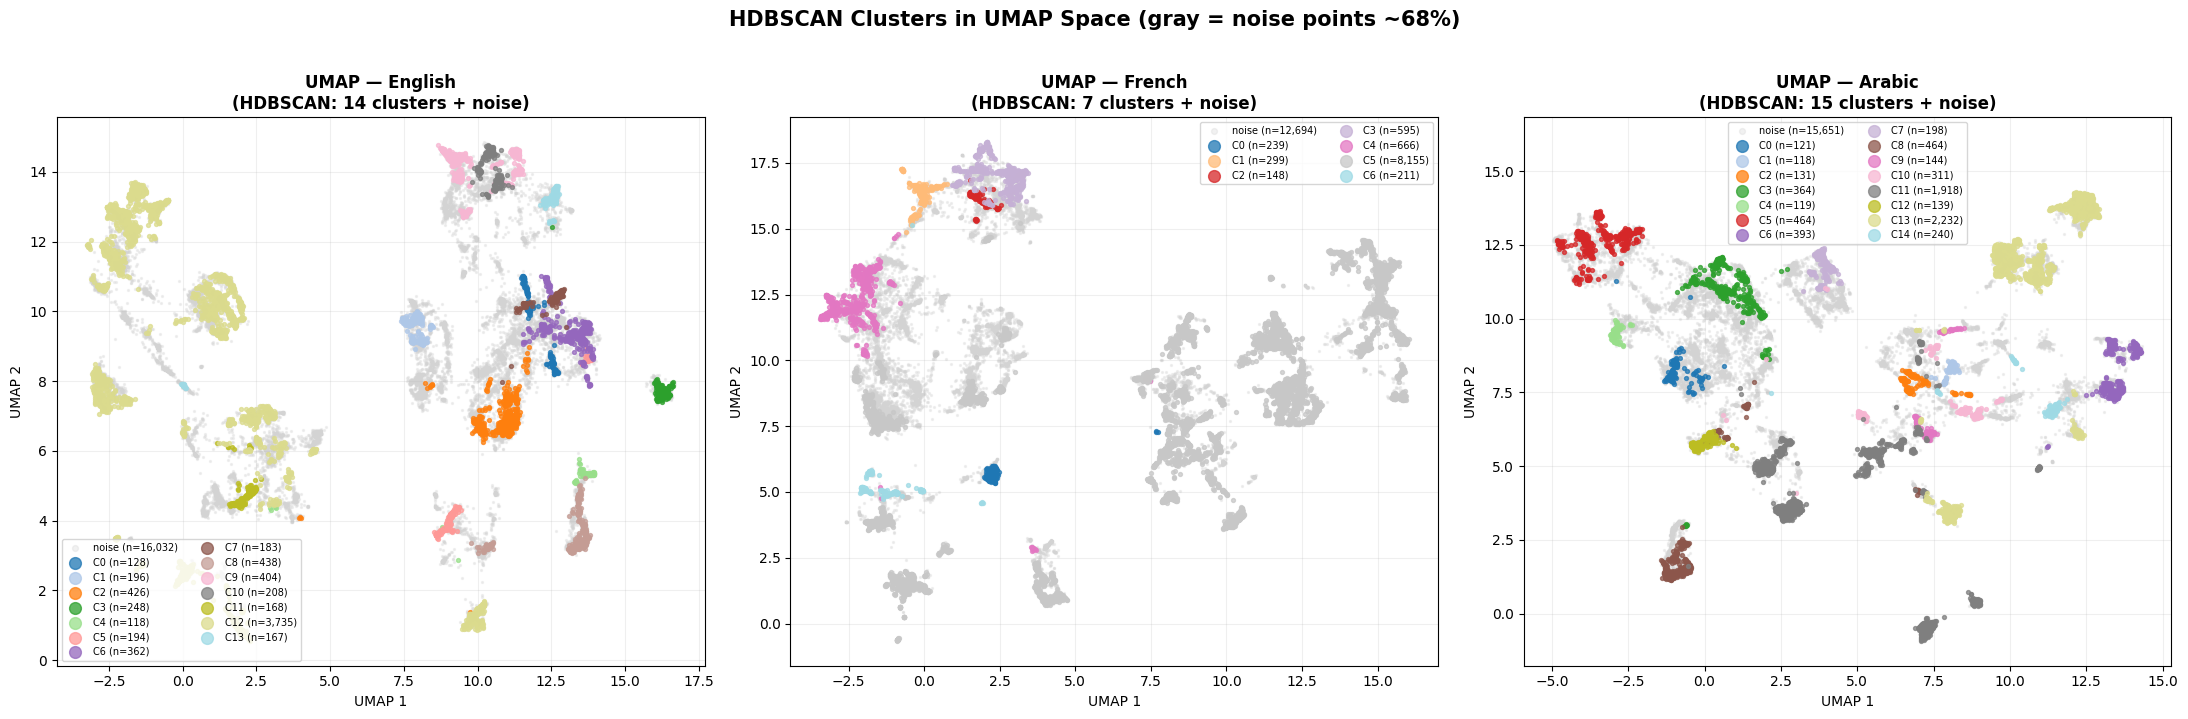

In [108]:

# 4.8: HDBSCAN UMAP Visualization — noise points as separate gray class
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
cmap_hdb = plt.cm.tab20

for ax, lang in zip(axes, LANGUAGES):
    c = clusters_per_language[lang]
    umap_2d = c['embeddings_umap']
    labels_raw = c['labels_hdbscan']

    unique_clusters = sorted([l for l in set(labels_raw) if l != -1])
    n_clusters = len(unique_clusters)
    cluster_colors = cmap_hdb(np.linspace(0, 0.95, n_clusters))

    # Plot noise first (gray, small, background)
    noise_mask = labels_raw == -1
    ax.scatter(umap_2d[noise_mask, 0], umap_2d[noise_mask, 1],
               c='lightgray', s=2, alpha=0.3, label=f'noise (n={noise_mask.sum():,})', zorder=1)

    # Plot clusters on top
    for cl_id, color in zip(unique_clusters, cluster_colors):
        mask = labels_raw == cl_id
        ax.scatter(umap_2d[mask, 0], umap_2d[mask, 1],
                   c=[color], s=8, alpha=0.75, label=f'C{cl_id} (n={mask.sum():,})', zorder=2)

    ax.set_title(f'UMAP — {lang_labels_map[lang]}\n(HDBSCAN: {n_clusters} clusters + noise)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.legend(markerscale=3, fontsize=7, loc='best', ncol=2)
    ax.grid(True, alpha=0.2)

plt.suptitle('HDBSCAN Clusters in UMAP Space (gray = noise points ~68%)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 4.9 HDBSCAN Accuracy Heatmap

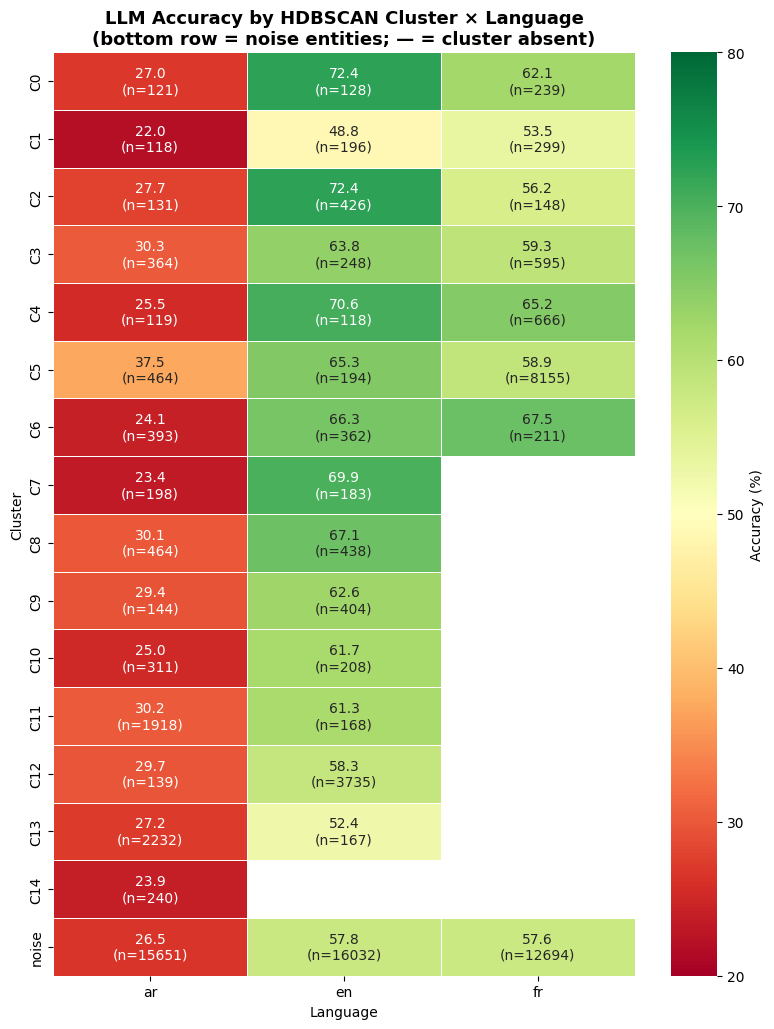

In [109]:

# 4.9: HDBSCAN Accuracy Heatmap (including noise as a class)
rows_hdb = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang]
    for cluster_id, grp in lang_df.groupby('cluster_hdbscan_labeled'):
        n_entities = grp['entity_id'].nunique()
        rows_hdb.append({
            'language': lang,
            'cluster': cluster_id,
            'accuracy': grp['is_correct'].mean(),
            'n': n_entities,
        })

heatmap_hdb = pd.DataFrame(rows_hdb).pivot(index='cluster', columns='language', values='accuracy') * 100
counts_hdb = pd.DataFrame(rows_hdb).pivot(index='cluster', columns='language', values='n')

# Sort: cluster ids first (numeric order), noise last
non_noise = sorted([i for i in heatmap_hdb.index if i != 'noise'], key=lambda x: int(x[1:]))
heatmap_hdb = pd.concat([heatmap_hdb.loc[non_noise], heatmap_hdb.loc[['noise']]])
counts_hdb = pd.concat([counts_hdb.loc[non_noise], counts_hdb.loc[['noise']]])

# Annotation: accuracy + entity count (NaN = cluster absent in that language)
annot = heatmap_hdb.copy().astype(object)
for idx in annot.index:
    for col in annot.columns:
        acc = heatmap_hdb.loc[idx, col]
        n = counts_hdb.loc[idx, col]
        if pd.isna(acc):
            annot.loc[idx, col] = '—'
        else:
            n_str = f'{int(n)}' if not pd.isna(n) else '?'
            annot.loc[idx, col] = f'{acc:.1f}\n(n={n_str})'

fig, ax = plt.subplots(figsize=(8, max(6, len(heatmap_hdb) * 0.65)))
sns.heatmap(heatmap_hdb, annot=annot, fmt='s', cmap='RdYlGn', vmin=20, vmax=80,
            ax=ax, cbar_kws={'label': 'Accuracy (%)'}, linewidths=0.5)
ax.set_title('LLM Accuracy by HDBSCAN Cluster × Language\n(bottom row = noise entities; — = cluster absent)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Language')
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.show()


### 4.10 Cluster Characterization via TF-IDF

Each cluster is treated as a "document" = bag of `country + culture + occupation_group` tokens from all its entities.
TF-IDF highlights which terms are most *distinctive* for each cluster (not just frequent overall).

In [110]:

from sklearn.feature_extraction.text import TfidfVectorizer


def characterize_clusters_tfidf(df, cluster_col, top_n=5):
    """
    Use TF-IDF on country + culture + occupation_group to characterize clusters.
    Each entity contributes one 'document'; clusters are aggregated as bags of tokens.
    """
    # Deduplicate: one row per entity (avoid LLM result duplication)
    entity_df = df.drop_duplicates(subset='entity_id').copy()
    entity_df['text'] = (
        entity_df['country'].fillna('').str.replace(' ', '_') + ' ' +
        entity_df['culture'].fillna('').str.replace(' ', '_') + ' ' +
        entity_df['occupation_group'].fillna('').str.replace(' ', '_')
    )
    cluster_docs = entity_df.groupby(cluster_col)['text'].apply(' '.join)
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(cluster_docs)
    feature_names = vectorizer.get_feature_names_out()

    results = {}
    for i, cluster_id in enumerate(cluster_docs.index):
        row = tfidf_matrix[i].toarray()[0]
        top_indices = row.argsort()[-top_n:][::-1]
        results[cluster_id] = [feature_names[j] for j in top_indices]
    return pd.DataFrame(results, index=[f'top_{i+1}' for i in range(top_n)]).T


print("=" * 70)
print("K-MEANS — TF-IDF Cluster Characterization (country + culture + occ.)")
print("=" * 70)
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang]
    result = characterize_clusters_tfidf(lang_df, 'cluster_kmeans')
    print(f"\n--- {lang_labels_map[lang]} ---")
    print(result.to_string())

print("\n" + "=" * 70)
print("HDBSCAN — TF-IDF Cluster Characterization")
print("=" * 70)
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang]
    result = characterize_clusters_tfidf(lang_df, 'cluster_hdbscan_labeled')
    print(f"\n--- {lang_labels_map[lang]} ---")
    print(result.to_string())


K-MEANS — TF-IDF Cluster Characterization (country + culture + occ.)

--- English ---
            top_1           top_2    top_3       top_4      top_5
0          sports  latin_american   arabic  east_asian    african
1  _entertainment           arts_  western  east_asian  politics_

--- French ---
            top_1           top_2    top_3       top_4      top_5
0  _entertainment           arts_  western  east_asian  politics_
1          sports  latin_american   arabic  east_asian    western

--- Arabic ---
            top_1           top_2       top_3       top_4      top_5
0  _entertainment           arts_     western  east_asian  politics_
1          sports  latin_american  east_asian     african     arabic

HDBSCAN — TF-IDF Cluster Characterization

--- English ---
                top_1        top_2           top_3           top_4           top_5
C0            western         _law       politics_  united_kingdom   united_states
C1     latin_american        chile          mexico   

### 4.11 Grouping Loss by Occupation Group

Does the LLM perform differently for athletes vs politicians vs scientists?
`occupation_group` is used as the grouping variable (5 categories from `selected_entities.csv`).

sex values: {'male': 159117, 'female': 45792}

✓ Grouping loss by demographic label

── Occupation ──
language        algorithm  n_groups  grouping_loss_variance  grouping_loss_gap
      en occupation_group         9                0.000906           0.101899
      fr occupation_group         9                0.000949           0.103111
      ar occupation_group         9                0.000142           0.046172 

── Sex ──
language algorithm  n_groups  grouping_loss_variance  grouping_loss_gap
      en       sex         2                0.000156           0.025009
      fr       sex         2                0.000238           0.030858
      ar       sex         2                0.000003           0.003182 

── Country ──
language algorithm  n_groups  grouping_loss_variance  grouping_loss_gap
      en   country        26                0.007303           0.342753
      fr   country        26                0.007427           0.336160
      ar   country        26                0.0015

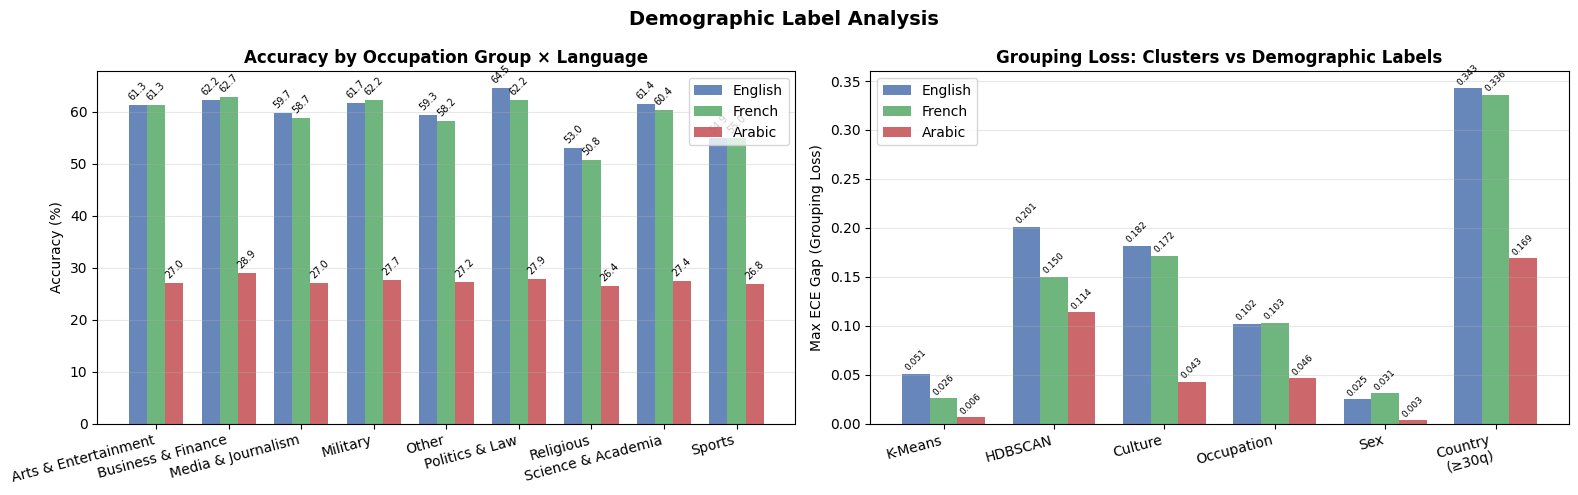

In [112]:

# 4.11: Grouping Loss by Demographic Labels (occupation, sex, country)
COUNTRY_MIN_Q = 30  # min questions per country per language

# ── occupation ────────────────────────────────────────────────────────────────
merged_df['occ_int'] = merged_df['occupation_group'].astype('category').cat.codes
occ_categories = dict(enumerate(merged_df['occupation_group'].astype('category').cat.categories))

occ_records = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang].copy()
    for qtype_filter, qtype_label in [(None, 'all'), ('birth_place', 'birth_place'),
                                       ('nationality', 'nationality'), ('birth_date', 'birth_date')]:
        sub = lang_df if qtype_filter is None else lang_df[lang_df['question_type'] == qtype_filter]
        gl = group_ece(sub, 'occ_int', exclude_noise=False)
        occ_records.append({
            'language': lang, 'algorithm': 'occupation_group', 'question_type': qtype_label,
            'n_groups': gl['n_groups'], 'grouping_loss_variance': gl['variance'],
            'grouping_loss_gap': gl['max_gap'], 'overall_accuracy': gl['overall_acc'],
            'group_accuracies': gl['group_accs'],
        })
occ_gl_df = pd.DataFrame(occ_records)

# ── sex ───────────────────────────────────────────────────────────────────────
# entities_df uses 'id'; merged_df uses 'entity_id' — same join pattern as occupation_group
if 'sex' not in merged_df.columns:
    merged_df = merged_df.merge(
        entities_df[['id', 'sex']].drop_duplicates('id'),
        left_on='entity_id', right_on='id', how='left'
    )
print(f"sex values: {merged_df['sex'].value_counts().to_dict()}")

merged_df['sex_int'] = merged_df['sex'].astype('category').cat.codes

sex_records = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang].dropna(subset=['sex']).copy()
    for qtype_filter, qtype_label in [(None, 'all'), ('birth_place', 'birth_place'),
                                       ('nationality', 'nationality'), ('birth_date', 'birth_date')]:
        sub = lang_df if qtype_filter is None else lang_df[lang_df['question_type'] == qtype_filter]
        gl = group_ece(sub, 'sex_int', exclude_noise=False)
        sex_records.append({
            'language': lang, 'algorithm': 'sex', 'question_type': qtype_label,
            'n_groups': gl['n_groups'], 'grouping_loss_variance': gl['variance'],
            'grouping_loss_gap': gl['max_gap'], 'overall_accuracy': gl['overall_acc'],
            'group_accuracies': gl['group_accs'],
        })
sex_gl_df = pd.DataFrame(sex_records)

# ── country (filtered) ────────────────────────────────────────────────────────
country_records = []
for lang in LANGUAGES:
    lang_df = merged_df[merged_df['language'] == lang].copy()
    valid = lang_df['country'].value_counts()
    valid = valid[valid >= COUNTRY_MIN_Q].index
    cdf = lang_df[lang_df['country'].isin(valid)].copy()
    cdf['country_int'] = cdf['country'].astype('category').cat.codes
    for qtype_filter, qtype_label in [(None, 'all'), ('birth_place', 'birth_place'),
                                       ('nationality', 'nationality'), ('birth_date', 'birth_date')]:
        sub = cdf if qtype_filter is None else cdf[cdf['question_type'] == qtype_filter]
        gl = group_ece(sub, 'country_int', exclude_noise=False)
        country_records.append({
            'language': lang, 'algorithm': 'country', 'question_type': qtype_label,
            'n_groups': gl['n_groups'], 'grouping_loss_variance': gl['variance'],
            'grouping_loss_gap': gl['max_gap'], 'overall_accuracy': gl['overall_acc'],
            'group_accuracies': gl['group_accs'],
        })
country_gl_df = pd.DataFrame(country_records)

# ── summary ───────────────────────────────────────────────────────────────────
_summary_cols = ['language', 'algorithm', 'n_groups', 'grouping_loss_variance', 'grouping_loss_gap']
print("\n✓ Grouping loss by demographic label\n")
for _df, _name in [(occ_gl_df, 'Occupation'), (sex_gl_df, 'Sex'), (country_gl_df, 'Country')]:
    print(f"── {_name} ──")
    print(_df[_df['question_type'] == 'all'][_summary_cols].to_string(index=False), '\n')

# ── Panel 1: accuracy per occupation group ────────────────────────────────────
occ_names = list(occ_categories.values())
colors_lang = {'en': '#4C72B0', 'fr': '#55A868', 'ar': '#C44E52'}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax1 = axes[0]
x = np.arange(len(occ_names))
width = 0.25
for i, lang in enumerate(LANGUAGES):
    lang_df = merged_df[merged_df['language'] == lang]
    accs = [lang_df[lang_df['occupation_group'] == occ]['is_correct'].mean() * 100
            for occ in occ_names]
    bars = ax1.bar(x + i * width, accs, width, label=lang_labels_map[lang],
                   color=colors_lang[lang], alpha=0.85)
    for bar, v in zip(bars, accs):
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                 f'{v:.1f}', ha='center', va='bottom', fontsize=7, rotation=45)
ax1.set_xticks(x + width)
ax1.set_xticklabels(occ_names, rotation=15, ha='right')
ax1.set_ylabel('Accuracy (%)')
ax1.set_title('Accuracy by Occupation Group × Language', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# ── Panel 2: grouping loss comparison — all labelling strategies ──────────────
ax2 = axes[1]
all_label_gl = pd.concat([gl_df, culture_gl_df, occ_gl_df, sex_gl_df, country_gl_df], ignore_index=True)
plot_data2 = all_label_gl[all_label_gl['question_type'] == 'all']

algo_order2 = ['kmeans', 'hdbscan', 'culture_baseline', 'occupation_group', 'sex', 'country']
algo_labels2 = {
    'kmeans': 'K-Means', 'hdbscan': 'HDBSCAN', 'culture_baseline': 'Culture',
    'occupation_group': 'Occupation', 'sex': 'Sex',
    'country': f'Country\n(≥{COUNTRY_MIN_Q}q)',
}
x2 = np.arange(len(algo_order2))
width2 = 0.25

for i, lang in enumerate(LANGUAGES):
    vals = []
    for algo in algo_order2:
        row = plot_data2[(plot_data2['language'] == lang) & (plot_data2['algorithm'] == algo)]
        vals.append(row['grouping_loss_gap'].values[0] if len(row) > 0 else 0)
    bars = ax2.bar(x2 + i * width2, vals, width2, label=lang_labels_map[lang],
                   color=colors_lang[lang], alpha=0.85)
    for bar, v in zip(bars, vals):
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
                 f'{v:.3f}', ha='center', va='bottom', fontsize=6.5, rotation=45)

ax2.set_xticks(x2 + width2)
ax2.set_xticklabels([algo_labels2[a] for a in algo_order2], rotation=15, ha='right')
ax2.set_ylabel('Max ECE Gap (Grouping Loss)')
ax2.set_title('Grouping Loss: Clusters vs Demographic Labels', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

plt.suptitle('Demographic Label Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
merged_df.columns

Index(['question_id', 'entity_id', 'question_type', 'language',
       'correct_answer', 'predicted_answer', 'is_correct', 'probabilities',
       'confidence', 'correct_prob', 'timestamp', 'id', 'culture', 'country',
       'wikidata_id', 'cluster_kmeans', 'cluster_hierarchical',
       'cluster_hdbscan', 'occupation_group', 'cluster_hdbscan_labeled',
       'occ_int'],
      dtype='object')

### 4.12 HDBSCAN Accuracy by Question Type

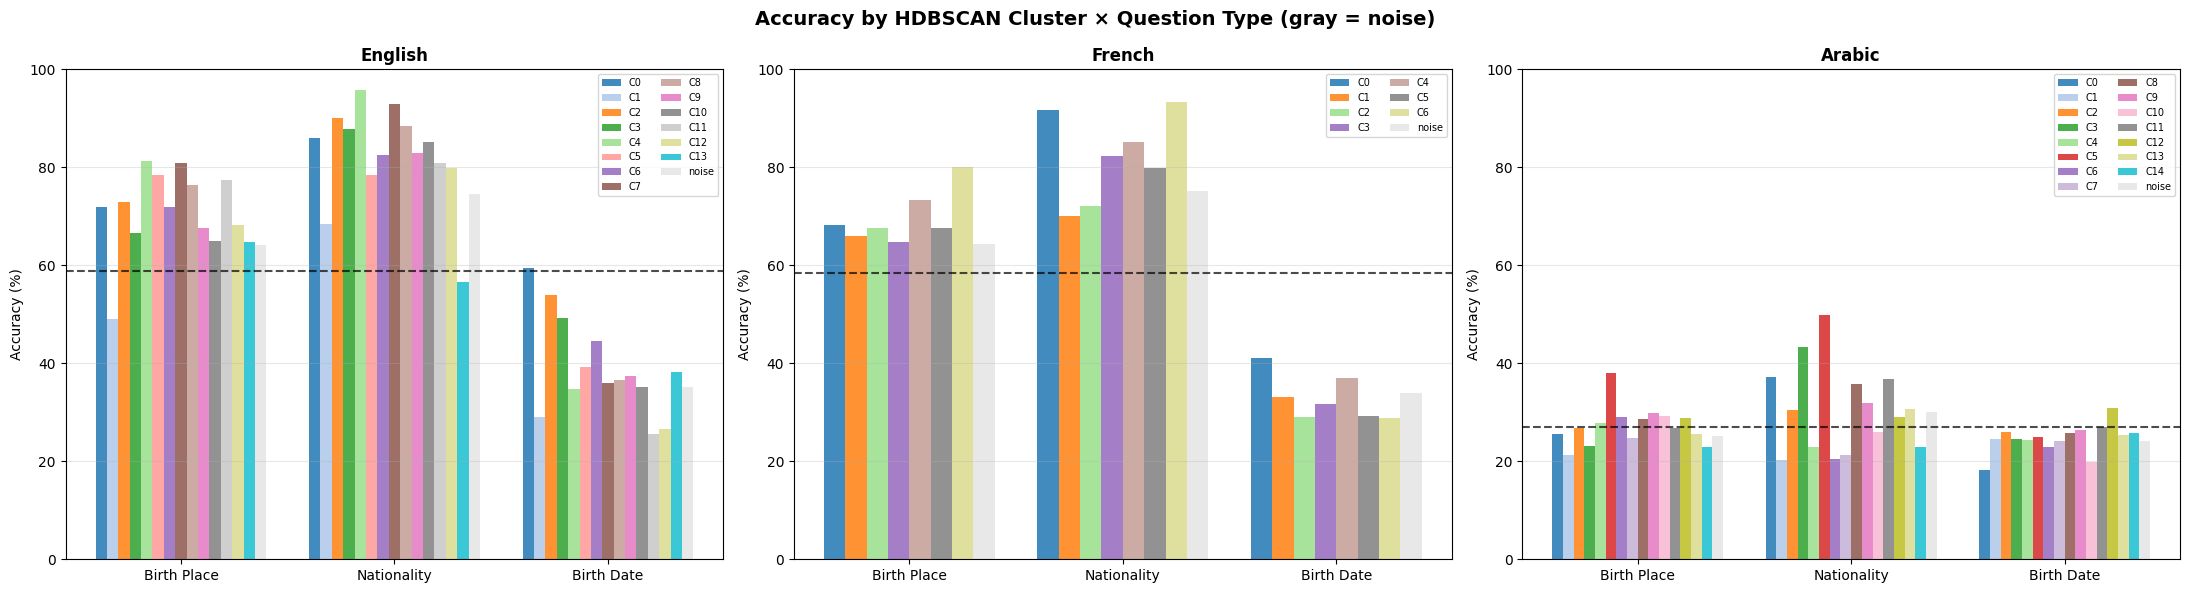

In [ ]:

# 4.12: HDBSCAN Accuracy by Cluster × Question Type
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, lang in zip(axes, LANGUAGES):
    lang_df = merged_df[merged_df['language'] == lang].copy()
    clusters = sorted([c for c in lang_df['cluster_hdbscan_labeled'].unique() if c != 'noise'],
                      key=lambda x: int(x[1:]))
    has_noise = 'noise' in lang_df['cluster_hdbscan_labeled'].unique()
    clusters_plot = clusters + (['noise'] if has_noise else [])

    x = np.arange(len(qtypes))
    n_c = len(clusters_plot)
    width = 0.8 / n_c
    cmap_hdb = plt.cm.tab20
    cluster_colors = [cmap_hdb(i / max(len(clusters), 1)) for i in range(len(clusters))]
    if has_noise:
        cluster_colors.append('lightgray')

    for i, (cid, color) in enumerate(zip(clusters_plot, cluster_colors)):
        sub = lang_df[lang_df['cluster_hdbscan_labeled'] == cid]
        accs = [sub[sub['question_type'] == qt]['is_correct'].mean() * 100 for qt in qtypes]
        ax.bar(x + i * width - (n_c - 1) * width / 2, accs, width,
               label=cid, color=color, alpha=0.5 if cid == 'noise' else 0.85)

    ax.set_xticks(x)
    ax.set_xticklabels([qtype_labels[q] for q in qtypes])
    ax.set_ylim(0, 100)
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'{lang_labels_map[lang]}', fontweight='bold')
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3, axis='y')
    overall = lang_df['is_correct'].mean() * 100
    ax.axhline(overall, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label=f'Overall {overall:.1f}%')

plt.suptitle('Accuracy by HDBSCAN Cluster × Question Type (gray = noise)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Section 5: Summary Table & Export

In [ ]:
summary = all_gl[all_gl['question_type'] == 'all'][
    ['language', 'algorithm', 'n_groups', 'grouping_loss_variance', 'grouping_loss_gap', 'overall_accuracy']
].copy()
summary['overall_accuracy'] = (summary['overall_accuracy'] * 100).round(2)
summary['grouping_loss_variance'] = summary['grouping_loss_variance'].round(5)
summary['grouping_loss_gap'] = summary['grouping_loss_gap'].round(4)
summary = summary.sort_values(['language', 'algorithm'])

print("=" * 80)
print("GROUPING LOSS SUMMARY (all question types)")
print("=" * 80)
print(summary.to_string(index=False))

# Save
out_path = Path('../data/experiment/natural_cluster_grouping_loss.csv')
all_gl.drop(columns=['group_accuracies']).to_csv(out_path, index=False)
print(f"\n✓ Full results saved to: {out_path}")